# sevendt_etc 예시 노트북 (v1.0.0)

7DT 노출시간 계산기(ETC) 사용 예시입니다. **등급과 목표 SNR을 넣으면 밴드별 노출시간**을 텍스트 리포트와 그림으로 돌려줍니다.

| 순서 | 내용 |
|---|---|
| 1 | 설치와 불러오기 |
| 2 | 관측 조건 |
| 3 | **calculate_exptime**: 등급 + SNR → 밴드별 노출시간 (메인 함수) |
| 4 | **observe_and_etc**: 추천 관측 시각 + 밴드별 노출시간 그림 + 텍스트 리포트 |
| 5 | 필터 선택 (`'all'`, `'available'`, 직접 지정) |
| 6 | 그 밖의 계산: SNR, 한계 등급 / 표면밝기 |
| 7 | 참고: noise budget, time–depth 그림 (보조 자료) |
| 8 | 5″ / 10″ 구경 비교 |
| 9 | 함수형 API (한 줄 계산) |

**관측 방식**: 총 노출시간은 **100 s 프레임**으로 나누어 촬영합니다. 결과의 `N_frame`은 필요한 프레임 수(= ceil(T / 100 s))입니다.

**적용 범위**: GAIN 2750, 1×1 binning. airmass 1.2–1.7, 평균적인 달 조건에서 가장 신뢰도가 높습니다.

## 1. 설치와 불러오기

```bash
pip install git+https://github.com/AstroWanni/7dt_etc.git
```

In [1]:
%matplotlib inline
import warnings
import pandas as pd
import sevendt_etc
from sevendt_etc import ExposureCalculator, observe_and_etc, resolve_conditions
pd.set_option('display.width', 200)
print('sevendt_etc', sevendt_etc.__version__)

sevendt_etc 1.0.0


## 2. 관측 조건

계산에 쓰이는 조건은 **moon phase, moon separation, airmass, seeing** 네 가지입니다.

- `ra`, `dec`, `obsdate`(UTC)를 주면 앞의 세 값은 자동으로 계산됩니다.
- 직접 지정할 수도 있습니다. 주지 않은 값은 기본값(moon phase 0.5, sep 90°, airmass 1.2, seeing 2.0″)을 씁니다.
- seeing은 계산되지 않으므로 필요하면 직접 넣습니다.

In [2]:
TARGET = dict(ra=30.968, dec=-4.245)                       # 예시 대상
OBSDATE = '2026-09-15T07:10:00'                            # UTC
cond_target = dict(**TARGET, obsdate=OBSDATE, seeing=2.0)  # 좌표 + 시각 -> 조건 자동 계산
cond_manual = dict(moon_phase=0.1, moon_separation=120, airmass=1.2, seeing=2.0)   # 조건 직접 지정
cond_auto = resolve_conditions(**cond_target)
print({k: round(v, 3) for k, v in cond_auto.items() if k in ('moon_phase', 'moon_separation', 'airmass', 'seeing')})

{'moon_phase': 0.183, 'moon_separation': 154.358, 'airmass': 1.116, 'seeing': 2.0}


## 3. calculate_exptime: 등급 + SNR → 밴드별 노출시간 (메인 함수)

`calc.calculate_exptime(filter, value, snr, ...)` 하나로 밴드별 필요 노출시간을 계산하고 리포트를 출력합니다.

| 리포트 항목 | 내용 |
|---|---|
| `[Detector]` | GAIN 2750, 1×1 / gain [e⁻/ADU] / read noise [e⁻/pix, 프레임당] / dark current [e⁻/s/pix] / 프레임 시간 (모든 밴드 공통) |
| `[Source]` | 점광원 / extended, 밝기, 목표 SNR, 구경(점광원) 또는 측정 면적(extended) |
| `[Conditions]` | 계산에 쓰인 대상, 시각, 달 위상·이격, airmass, seeing |
| `sky` | 그 조건에서 예상되는 하늘 밝기 [mag/arcsec²], [e⁻/s/pix] |
| `skysig` | 100 s 프레임 한 장의 픽셀당 배경 노이즈 (sky + dark + read) [e⁻], [ADU] |
| `T_exp` | 목표 SNR에 필요한 총 노출시간 [s] |
| `N_frame` | 필요한 100 s 프레임 수 |

### 3-1. 점광원: 19.5 mag, SNR 5 (대상 좌표와 시각으로 조건 계산)

In [3]:
calc = ExposureCalculator()          # 10" aperture (기본)
res = calc.calculate_exptime('all', 19.5, snr=5, **cond_target)

7DT Exposure Time Calculator (sevendt_etc 1.0.0)
[Detector]
Setting        : GAIN 2750, 1x1 binning, pixel scale = 0.505 "/pix
Gain           : 0.256 e-/ADU
Read noise     : 1.50 e-/pix (per frame)
Dark current   : 0.0005 e-/s/pix
Frame          : 100 s per frame (N_frame = number of frames)

[Source]
Source         : point source, 19.5 mag (AB), target SNR = 5
Measurement    : aperture diameter = 10", enclosed pixels = 308.0

[Conditions]
Target         : RA = 30.9680, Dec = -4.2450 deg
Obsdate        : 2026-09-15 07:10:00 UTC
Moon           : phase = 0.18, separation = 154.4 deg
Airmass        : 1.12
Seeing         : 2.00 arcsec

[Exposure time per band]  (skysig: per pixel, one 100 s frame)
filter       sky        sky  skysig  skysig      T_exp  N_frame
       [mag/as2] [e-/s/pix]    [e-]   [ADU]        [s]
g          21.95     0.3217    5.87   22.93       24.3        1
r          20.92     0.5438    7.53   29.41       73.9        1
i          20.11     0.3212    5.87   22.92      5

결과는 밴드별 dict입니다. 표로 바꾸면 필요한 값만 골라 쓸 수 있습니다.

In [4]:
pd.DataFrame(res).T[['exptime', 'n_frame', 'mu_sky', 'sky_rate', 'skysig_e', 'skysig_adu']].astype(float).round(3).head(8)

,exptime,n_frame,mu_sky,sky_rate,skysig_e,skysig_adu
g,24.252,1.0,21.946,0.322,5.871,22.934
r,73.887,1.0,20.923,0.544,7.528,29.408
i,556.697,6.0,20.111,0.321,5.867,22.917
m400,456.403,5.0,23.543,0.005,1.659,6.481
m425,190.063,2.0,22.780,0.017,1.997,7.800
m450,172.315,2.0,22.475,0.027,2.227,8.701
m475,169.175,2.0,22.344,0.032,2.341,9.146
m500,172.603,2.0,22.092,0.043,2.569,10.035


### 3-2. extended source: 24 mag/arcsec², 측정 면적 100 arcsec², SNR 5

`mode='extended'`와 측정 면적 `area` [arcsec²]를 줍니다. 값은 mag/arcsec² 단위입니다.

In [5]:
_ = calc.calculate_exptime('all', 24.0, snr=5, mode='extended', area=100, **cond_manual)

7DT Exposure Time Calculator (sevendt_etc 1.0.0)
[Detector]
Setting        : GAIN 2750, 1x1 binning, pixel scale = 0.505 "/pix
Gain           : 0.256 e-/ADU
Read noise     : 1.50 e-/pix (per frame)
Dark current   : 0.0005 e-/s/pix
Frame          : 100 s per frame (N_frame = number of frames)

[Source]
Source         : extended source, 24 mag/arcsec^2, target SNR = 5
Measurement    : area = 100 arcsec^2 (392.1 pixels)

[Conditions]
Moon           : phase = 0.10, separation = 120.0 deg
Airmass        : 1.20
Seeing         : 2.00 arcsec

[Exposure time per band]  (skysig: per pixel, one 100 s frame)
filter       sky        sky  skysig  skysig      T_exp  N_frame
       [mag/as2] [e-/s/pix]    [e-]   [ADU]        [s]
g          21.96     0.3164    5.83   22.76       14.2        1
r          20.92     0.5444    7.53   29.42       39.5        1
i          20.16     0.3055    5.73   22.39      271.5        3
m400       24.26     0.0023    1.59    6.22      242.7        3
m425       22.64     

### 3-3. 밴드마다 다른 등급 / SNR

`filter`와 같은 길이의 리스트로 주면 밴드별로 다른 값을 씁니다. 이때 리포트에 `value`, `SNR` 열이 추가됩니다.

In [6]:
_ = calc.calculate_exptime(['m400', 'm500', 'm600'], [19.0, 19.5, 20.0], snr=[5, 10, 10], **cond_manual)

7DT Exposure Time Calculator (sevendt_etc 1.0.0)
[Detector]
Setting        : GAIN 2750, 1x1 binning, pixel scale = 0.505 "/pix
Gain           : 0.256 e-/ADU
Read noise     : 1.50 e-/pix (per frame)
Dark current   : 0.0005 e-/s/pix
Frame          : 100 s per frame (N_frame = number of frames)

[Source]
Source         : point source, per filter [mag (AB)], target SNR = per filter
Measurement    : aperture diameter = 10", enclosed pixels = 308.0

[Conditions]
Moon           : phase = 0.10, separation = 120.0 deg
Airmass        : 1.20
Seeing         : 2.00 arcsec

[Exposure time per band]  (skysig: per pixel, one 100 s frame)
filter   value   SNR       sky        sky  skysig  skysig      T_exp  N_frame
                     [mag/as2] [e-/s/pix]    [e-]   [ADU]        [s]
m400     19.00   5.0     24.26     0.0023    1.59    6.22      179.6        2
m500     19.50  10.0     22.08     0.0436    2.58   10.08      671.5        7
m600     20.00  10.0     21.06     0.0920    3.39   13.25     3958.

## 4. observe_and_etc: 추천 관측 시각 + 밴드별 노출시간

날짜(현지 기준 밤 시작일)와 대상 좌표를 주면 그날 밤 **airmass가 가장 낮은 시각을 추천 관측 시각**으로 잡고, 그 시각의 조건으로 밴드별 노출시간을 계산합니다.

- **텍스트**: 3절 리포트 + `[Observation plan]` (박명 시각, 고도 30° 이상 시간대, 추천 관측 시각)
- **위 그림**: 대상·달 고도, airmass 축, 관측 불가 영역(회색), 추천 시각(빨간 선)
- **아래 그림**: 밴드별 총 노출시간, ⚠ / `!`는 `warn_threshold`(기본 3600 s)보다 긴 경우

`save_path`로 그림을, `report_path`로 텍스트 리포트를 파일로 저장할 수 있습니다. 유저에게는 두 파일을 함께 전달하면 됩니다.

### 4-1. 점광원: 19.5 mag, SNR 5

7DT Exposure Time Calculator (sevendt_etc 1.0.0)
[Detector]
Setting        : GAIN 2750, 1x1 binning, pixel scale = 0.505 "/pix
Gain           : 0.256 e-/ADU
Read noise     : 1.50 e-/pix (per frame)
Dark current   : 0.0005 e-/s/pix
Frame          : 100 s per frame (N_frame = number of frames)

[Source]
Source         : point source, 19.5 mag (AB), target SNR = 5
Measurement    : aperture diameter = 10", enclosed pixels = 308.0

[Conditions]
Target         : RA = 30.9680, Dec = -4.2450 deg
Obsdate        : 2026-09-15 07:10:50 UTC
Moon           : phase = 0.18, separation = 154.4 deg
Airmass        : 1.12
Seeing         : 2.00 arcsec

[Observation plan]
Night          : 2026-09-14 (local)
Twilight       : 2026-09-14 23:54 -> 2026-09-15 09:21 UTC (astronomical)
Above 30 deg   : 2026-09-15 03:23 -> 2026-09-15 09:21 UTC (6.0 h)
Recommended    : 2026-09-15 07:10:50 UTC (lowest airmass), alt = 63.6 deg

[Exposure time per band]  (skysig: per pixel, one 100 s frame)
filter       sky        sky 

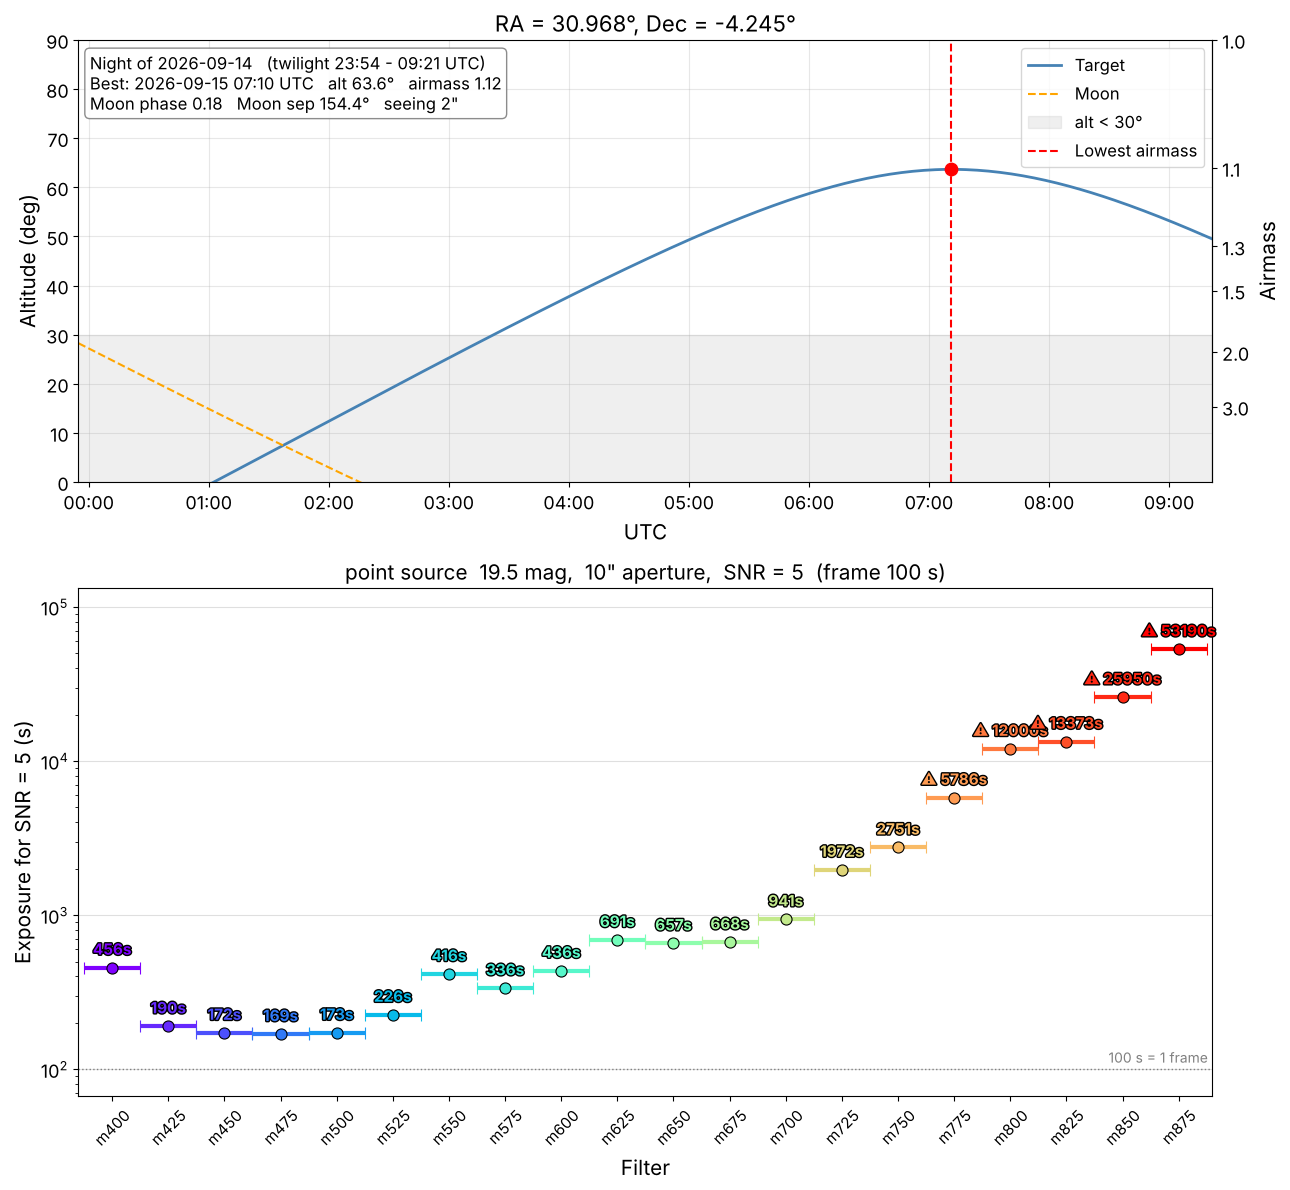

In [7]:
res_pt, info_pt = observe_and_etc(**TARGET, date='2026-09-14', value=19.5, snr=5, seeing=2.0,
                                  save_path='etc_point.png', report_path='etc_point.txt')

반환값 `info`에는 관측 계획 정보와 리포트 문자열(`info['report']`)이, `res`에는 밴드별 계산 결과가 들어 있습니다.

In [8]:
print({k: info_pt[k] for k in ('best_time_utc', 'best_alt', 'airmass', 'moon_phase', 'moon_sep', 'hours_above_min_alt')})
pd.DataFrame(res_pt).T[['exptime', 'n_frame', 'mu_sky', 'skysig_e']].astype(float).round(2).head(5)

{'best_time_utc': '2026-09-15 07:10:50.779', 'best_alt': 63.64275938622841, 'airmass': 1.116017448096226, 'moon_phase': 0.18307480578753044, 'moon_sep': 154.3538088088821, 'hours_above_min_alt': 5.982121714577079}


,exptime,n_frame,mu_sky,skysig_e
m400,456.43,5.0,23.54,1.66
m425,190.08,2.0,22.78,2.00
m450,172.33,2.0,22.47,2.23
m475,169.19,2.0,22.34,2.34
m500,172.62,2.0,22.09,2.57


### 4-2. extended source: 24 mag/arcsec², 면적 100 arcsec², SNR 5

7DT Exposure Time Calculator (sevendt_etc 1.0.0)
[Detector]
Setting        : GAIN 2750, 1x1 binning, pixel scale = 0.505 "/pix
Gain           : 0.256 e-/ADU
Read noise     : 1.50 e-/pix (per frame)
Dark current   : 0.0005 e-/s/pix
Frame          : 100 s per frame (N_frame = number of frames)

[Source]
Source         : extended source, 24 mag/arcsec^2, target SNR = 5
Measurement    : area = 100 arcsec^2 (392.1 pixels)

[Conditions]
Target         : RA = 30.9680, Dec = -4.2450 deg
Obsdate        : 2026-09-15 07:10:50 UTC
Moon           : phase = 0.18, separation = 154.4 deg
Airmass        : 1.12
Seeing         : 2.00 arcsec

[Observation plan]
Night          : 2026-09-14 (local)
Twilight       : 2026-09-14 23:54 -> 2026-09-15 09:21 UTC (astronomical)
Above 30 deg   : 2026-09-15 03:23 -> 2026-09-15 09:21 UTC (6.0 h)
Recommended    : 2026-09-15 07:10:50 UTC (lowest airmass), alt = 63.6 deg

[Exposure time per band]  (skysig: per pixel, one 100 s frame)
filter       sky        sky  skysig  

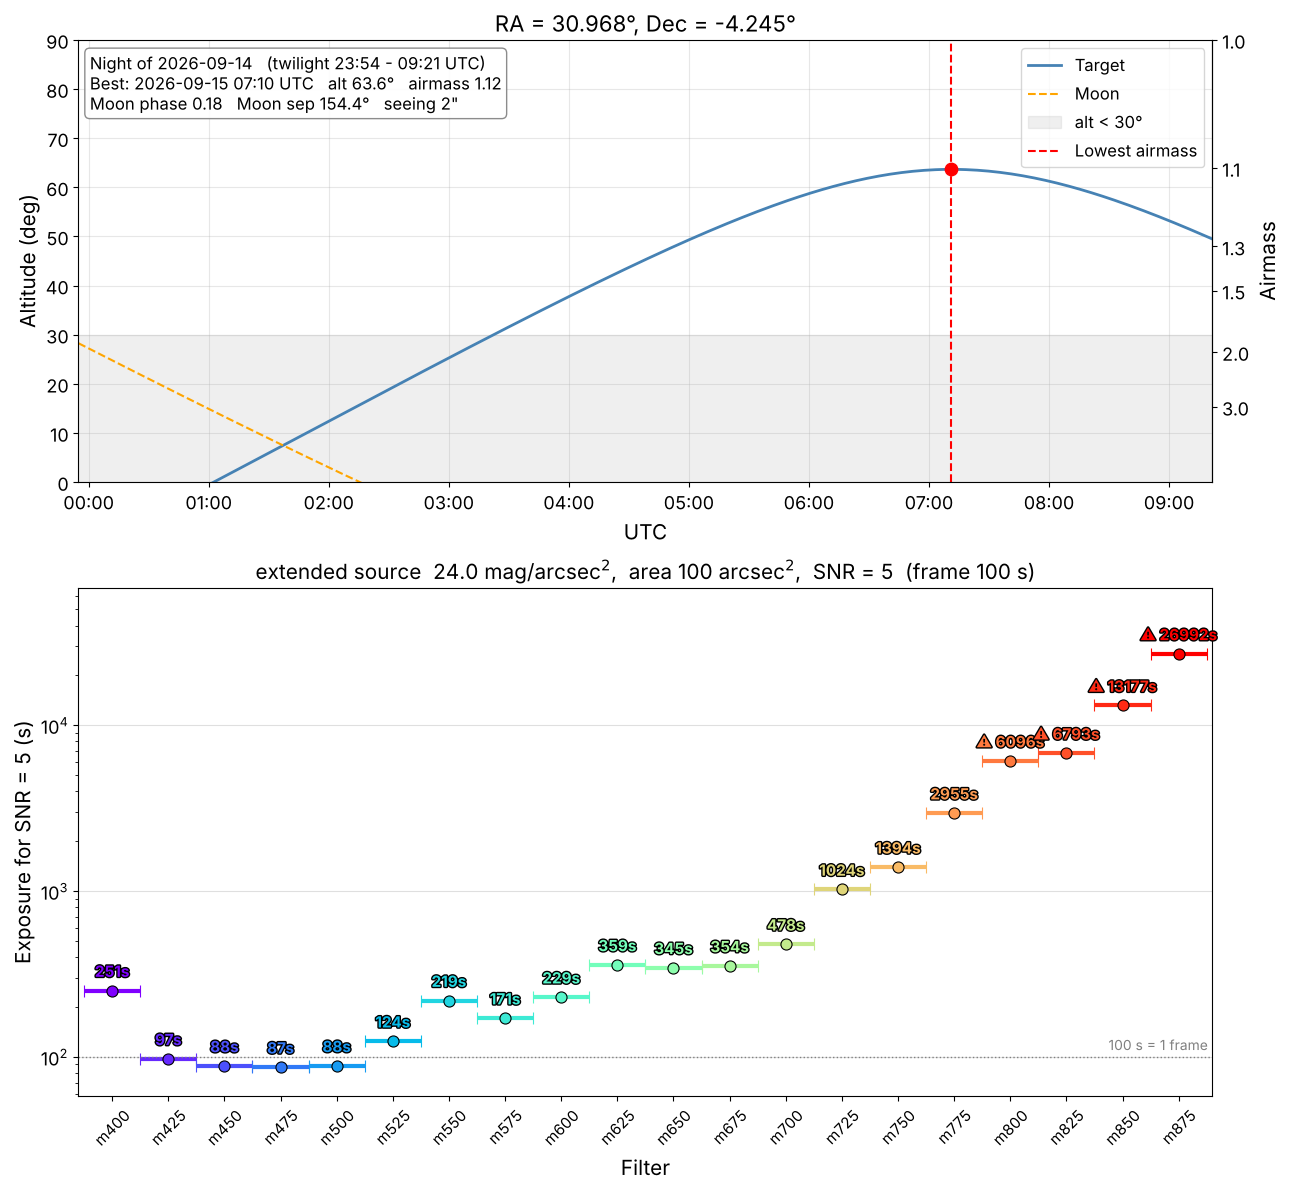

In [9]:
res_ex, info_ex = observe_and_etc(**TARGET, date='2026-09-14', value=24.0, snr=5, mode='extended', area=100, seeing=2.0)

## 5. 필터 선택

`filter`(함수형 API와 `observe_and_etc`에서는 `filters` / `bands`)에는 다음을 줄 수 있습니다.

| 입력 | 의미 |
|---|---|
| `'all'` | g, r, i, m400–m875 (25 nm 간격) — 기본 밴드 |
| `'available'` | 모델에 들어 있는 모든 밴드 (z, m438 등 추가 밴드 포함) |
| `'m500'` 또는 `['m400', 'm650']` | 이름으로 직접 지정 |

추가 밴드(z, m438, m483, m512, m534, m561, m586, m615, m640, m661, m769w, m832w)는 학습 프레임이 적거나 밴드 폭이 달라 `'all'`에서 빠집니다. 이름으로 지정하면 경고와 함께 계산됩니다.

`specred`, `specblue` 같은 필터 조합 이름은 아직 정의되지 않았습니다 (아래 셀의 주석 참고). 필요한 조합은 리스트로 만들어 넘기면 됩니다.

In [10]:
# 필터 조합 문자열 (예정, 아직 정의되지 않음)
# specred  = []
# specblue = []
# 'all'      : g, r, i, m400-m875 (25 nm 간격)
# 'available': 모델에 있는 모든 밴드
print("'all'      :", calc.filter_list('all'))
print("'available':", calc.filter_list('available'))
my_bands = ['g', 'r', 'm450', 'm650']                      # 직접 만든 조합
_ = calc.calculate_exptime(my_bands, 19.5, snr=5, **cond_manual)

'all'      : ['g', 'r', 'i', 'm400', 'm425', 'm450', 'm475', 'm500', 'm525', 'm550', 'm575', 'm600', 'm625', 'm650', 'm675', 'm700', 'm725', 'm750', 'm775', 'm800', 'm825', 'm850', 'm875']
'available': ['g', 'r', 'i', 'z', 'm400', 'm425', 'm438', 'm450', 'm475', 'm483', 'm500', 'm512', 'm525', 'm534', 'm550', 'm561', 'm575', 'm586', 'm600', 'm615', 'm625', 'm640', 'm650', 'm661', 'm675', 'm700', 'm725', 'm750', 'm769w', 'm775', 'm800', 'm825', 'm832w', 'm850', 'm875']
7DT Exposure Time Calculator (sevendt_etc 1.0.0)
[Detector]
Setting        : GAIN 2750, 1x1 binning, pixel scale = 0.505 "/pix
Gain           : 0.256 e-/ADU
Read noise     : 1.50 e-/pix (per frame)
Dark current   : 0.0005 e-/s/pix
Frame          : 100 s per frame (N_frame = number of frames)

[Source]
Source         : point source, 19.5 mag (AB), target SNR = 5
Measurement    : aperture diameter = 10", enclosed pixels = 308.0

[Conditions]
Moon           : phase = 0.10, separation = 120.0 deg
Airmass        : 1.20
Seeing 

In [11]:
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    calc.calculate_exptime('m512', 19.5, snr=5, verbose=False, **cond_manual)
    print('warning:', w[0].message if w else None)

## 6. 그 밖의 계산: SNR, 한계 등급 / 표면밝기

| 함수 | 입력 | 출력 |
|---|---|---|
| `calculate_exptime` | 밝기, 목표 SNR | 필요 총 노출시간, 프레임 수, sky, skysig (3절) |
| `calculate_snr` | 밝기, 총 노출시간 | SNR, 분산 구성 비율 |
| `calculate_limit` | 총 노출시간, SNR | 한계 등급 또는 한계 표면밝기 |

프레임마다 read noise가 한 번씩 더해지므로 101 s(2장)는 100 s(1장)보다 SNR이 약간 낮을 수 있습니다. 실제 관측은 100 s 단위로 잡는 것이 효율적입니다.

In [12]:
BANDS = ['m400', 'm500', 'm600', 'm700', 'm800']
_ = calc.calculate_snr(BANDS, 19.5, exptime=300, **cond_manual)
_ = calc.calculate_snr('m500', 21.0, exptime=[50, 100, 101, 200, 350], **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 10" aperture
Frame = 100 s
filter   value      T[s]      SNR  N_frame
m400     19.50     300.0     4.36        3
m500     19.50     300.0     6.73        3
m600     19.50     300.0     4.33        3
m700     19.50     300.0     2.76        3
m800     19.50     300.0     0.78        3
(value / limit in mag)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 10" aperture
Frame = 100 s
filter   value      T[s]      SNR  N_frame
m500     21.00      50.0     0.62        1
m500     21.00     100.0     1.01        1
m500     21.00     101.0     0.88        2
m500     21.00     200.0     1.42        2
m500     21.00     350.0     1.84        4
(value / limit in mag)



In [13]:
_ = calc.calculate_limit(BANDS, exptime=300, snr=5, **cond_manual)
_ = calc.calculate_limit(BANDS, exptime=600, snr=3, mode='extended', area=100, **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 10" aperture
Frame = 100 s
filter      T[s]   SNR   limit  N_frame
m400       300.0   5.0   19.34        3
m500       300.0   5.0   19.83        3
m600       300.0   5.0   19.34        3
m700       300.0   5.0   18.84        3
m800       300.0   5.0   17.45        3
(value / limit in mag)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Extended source, area = 100 arcsec^2
Frame = 100 s
filter      T[s]   SNR   limit  N_frame
m400       600.0   3.0   25.18        6
m500       600.0   3.0   25.66        6
m600       600.0   3.0   25.16        6
m700       600.0   3.0   24.66        6
m800       600.0   3.0   23.27        6
(value / limit in mag/arcsec^2)



## 7. 참고: 보조 그림

아래 그림은 노출시간 결정의 근거를 확인하는 **보조 자료**입니다. 유저 안내의 기본 출력은 3–4절의 리포트와 그림입니다.

모든 그림에 계산 조건이 상자로 표시되고, `save_path='파일명.png'`로 저장할 수 있습니다. 중대역 색상은 m400(보라)–m875(빨강) 고정 스케일입니다.

### 7-1. Noise budget

노출시간에 따라 어떤 노이즈(source, sky, dark, read)가 지배하는지 보여줍니다. 짧은 노출은 read noise, 긴 노출은 sky가 지배합니다.

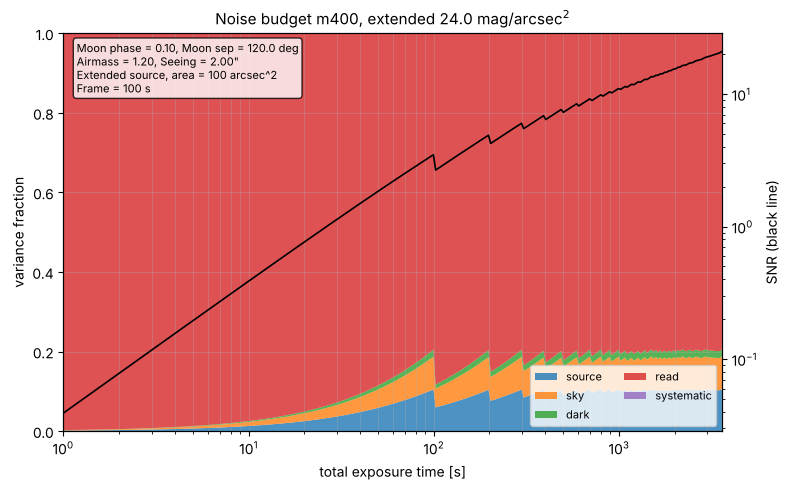

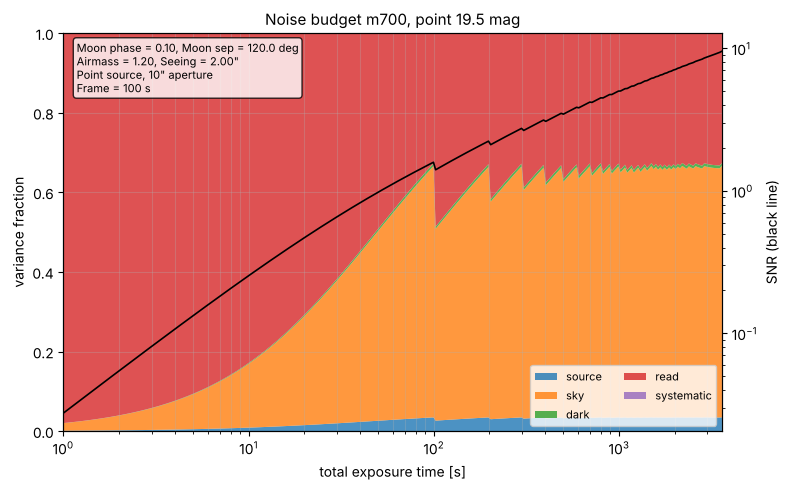

In [14]:
calc.plot_noise_budget('m400', 24.0, mode='extended', area=100, **cond_manual)
calc.plot_noise_budget('m700', 19.5, **cond_manual)

### 7-2. Time–depth (노출시간에 따른 한계 등급 / 표면밝기)

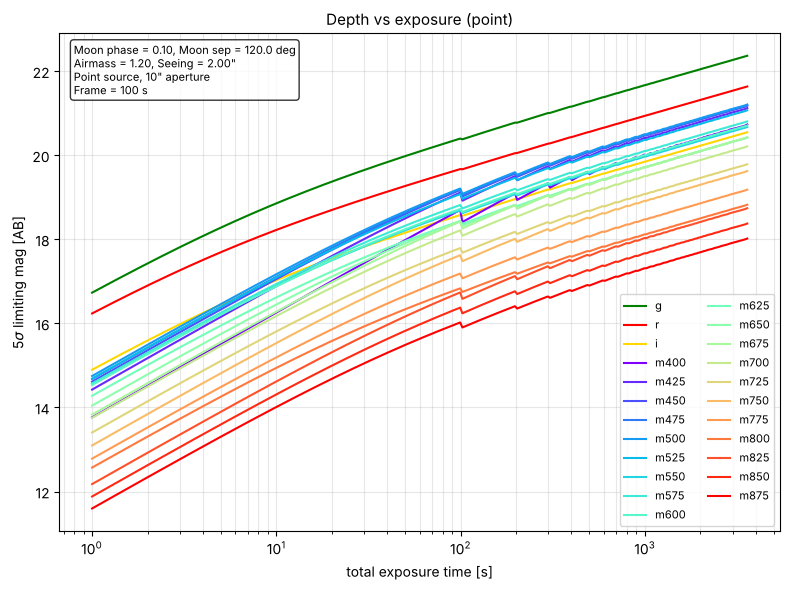

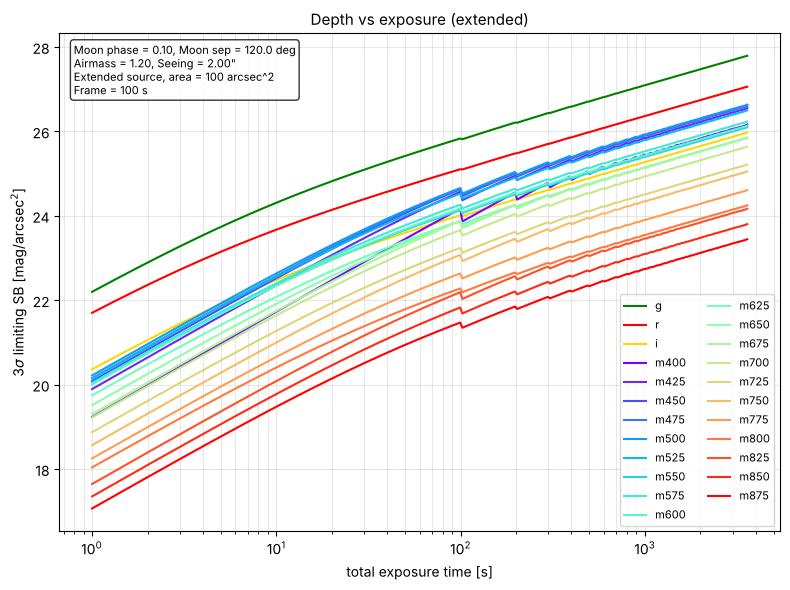

In [15]:
calc.plot_limit_vs_exptime('all', snr=5, **cond_manual)
calc.plot_limit_vs_exptime('all', snr=3, mode='extended', area=100, **cond_manual)

### 7-3. SNR–노출시간 관계

점선(점광원)은 100 s depth를 √t로 단순 확장한 값입니다. 짧은 노출에서는 read noise 때문에 실제 SNR(실선)이 더 낮습니다.

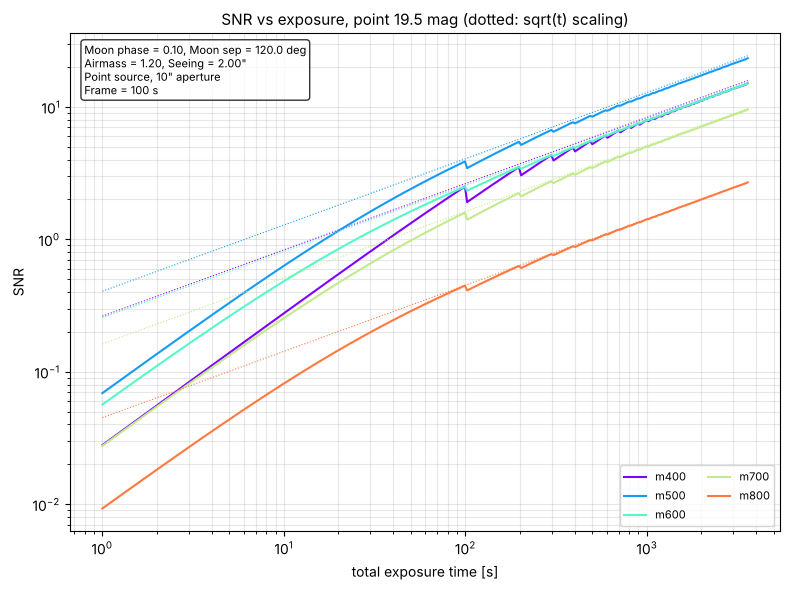

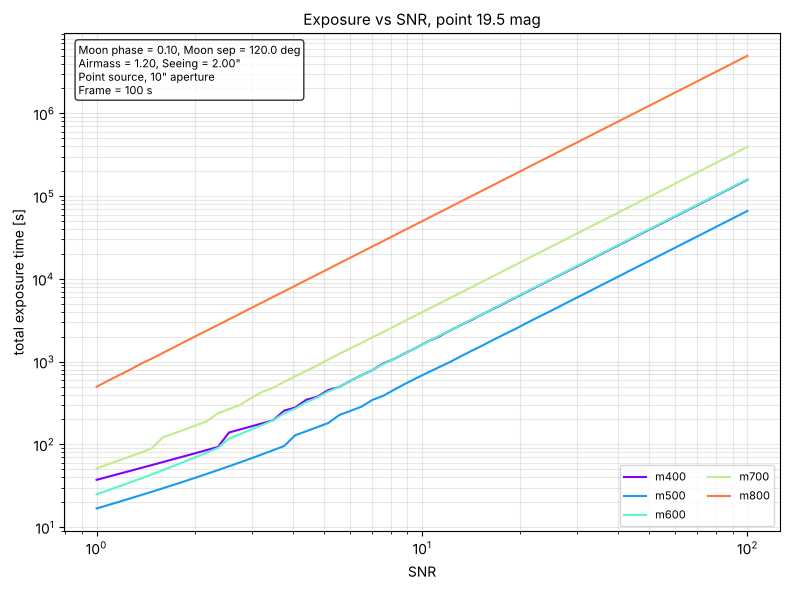

In [16]:
calc.plot_snr_vs_exptime(BANDS, 19.5, exptime_range=(1, 3600), **cond_manual)
calc.plot_exptime_vs_snr(BANDS, 19.5, snr_range=(1, 100), **cond_manual)

## 8. 5″ / 10″ 구경 비교 (점광원)

`ExposureCalculator(aperture=5)`로 5″ 구경 모델을 씁니다. 점광원은 작은 구경에서 sky 노이즈가 줄어 노출시간이 짧아지지만, seeing이 나쁘면 구경 밖으로 빠지는 빛이 늘어납니다.

In [17]:
calc5 = ExposureCalculator(aperture=5)
t10 = calc.calculate_exptime(BANDS, 19.5, snr=5, verbose=False, **cond_manual)
t5 = calc5.calculate_exptime(BANDS, 19.5, snr=5, verbose=False, **cond_manual)
pd.DataFrame({'T_10" [s]': {f: t10[f]['exptime'] for f in BANDS}, 'T_5" [s]': {f: t5[f]['exptime'] for f in BANDS}}).assign(
    ratio=lambda d: d['T_5" [s]'] / d['T_10" [s]']).round(2)

,"T_10"" [s]","T_5"" [s]",ratio
m400,397.12,176.03,0.44
m500,173.54,69.79,0.40
m600,399.35,148.75,0.37
m700,988.74,355.34,0.36
m800,12439.74,3856.01,0.31


## 9. 함수형 API (한 줄 계산)

계산기 객체 없이 바로 계산합니다. `aperture=5`로 5″ 모델을 선택합니다.

In [18]:
_ = sevendt_etc.calculate_exptime(19.5, snr=10, filters=['m400', 'm650'], **cond_manual)
_ = sevendt_etc.calculate_limit(300, snr=3, filters=['m400', 'm650'], mode='extended', area=100, **cond_manual)

7DT Exposure Time Calculator (sevendt_etc 1.0.0)
[Detector]
Setting        : GAIN 2750, 1x1 binning, pixel scale = 0.505 "/pix
Gain           : 0.256 e-/ADU
Read noise     : 1.50 e-/pix (per frame)
Dark current   : 0.0005 e-/s/pix
Frame          : 100 s per frame (N_frame = number of frames)

[Source]
Source         : point source, 19.5 mag (AB), target SNR = 10
Measurement    : aperture diameter = 10", enclosed pixels = 308.0

[Conditions]
Moon           : phase = 0.10, separation = 120.0 deg
Airmass        : 1.20
Seeing         : 2.00 arcsec

[Exposure time per band]  (skysig: per pixel, one 100 s frame)
filter       sky        sky  skysig  skysig      T_exp  N_frame
       [mag/as2] [e-/s/pix]    [e-]   [ADU]        [s]
m400       24.26     0.0023    1.59    6.22     1588.5       16
m650       21.14     0.0544    2.78   10.87     2682.7       27

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Extended source, area = 100 arcsec^2
Frame = 100 s
filter      T[s]